# 01 · Data audit, cleaning and operational KPIs

**Question:** how healthy is order fulfilment, and where is revenue exposed?

This notebook is the Python twin of `sql/01–03`. Everything comes from the tested `autosales` package, so the numbers here match SQL and Power BI exactly.

| Step | Python | SQL equivalent |
|---|---|---|
| Raw landing | `load_raw()` | `bronze.auto_sales_raw` |
| Clean & type | `build_order_lines()` | `silver.order_lines` |
| One row per order | `build_order_summary()` | `gold.order_summary` |

In [1]:
import sys
from pathlib import Path

# make the src/ package importable from notebooks/ (no hard-coded C:\ paths)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 1 else f"{v:,.2f}")

from autosales.data import load_raw, build_order_lines, build_order_summary, build_customer_features
from autosales import kpis, segmentation, clustering, modelling, plots
%matplotlib inline

## 1. Raw data: what did we receive?

In [2]:
raw = load_raw()
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns")
raw.head(3)

2,747 rows × 20 columns


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871,24/02/2018,828,Shipped,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small
1,10121,34,81.35,5,2765.9,07/05/2018,757,Shipped,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,01/07/2018,703,Shipped,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium


## 2. Clean and type (silver)
Text is converted to proper types, the status is mapped to a business group, and personal data (phone, address, postcode) is dropped because nothing downstream needs it.

In [3]:
lines = build_order_lines(raw)
print("unparsed values:", int(lines[["order_date", "quantity", "price_each", "sales", "msrp"]].isna().sum().sum()))
print("date range:", lines.order_date.min().date(), "→", lines.order_date.max().date())
lines[["order_number", "order_line_number", "order_date", "customer_name", "product_line", "status", "status_group", "sales"]].head()

unparsed values: 0
date range: 2018-01-06 → 2020-05-31


,order_number,order_line_number,order_date,customer_name,product_line,status,status_group,sales
0,10107,2,2018-02-24,Land of Toys Inc.,Motorcycles,SHIPPED,Fulfilled,"2,871.00"
1,10121,5,2018-05-07,Reims Collectables,Motorcycles,SHIPPED,Fulfilled,"2,765.90"
2,10134,2,2018-07-01,Lyon Souveniers,Motorcycles,SHIPPED,Fulfilled,"3,884.34"
3,10145,6,2018-08-25,Toys4GrownUps.com,Motorcycles,SHIPPED,Fulfilled,"3,746.70"
4,10168,1,2018-10-28,Technics Stores Inc.,Motorcycles,SHIPPED,Fulfilled,"3,479.76"


## 3. Data-quality checks
These are the assumptions the order-level table relies on. The same checks run in SQL (`sql/05_data_quality_tests.sql`) and in `pytest`.

In [4]:
checks = {
    "duplicate order-line keys": int(lines.duplicated(["order_number", "order_line_number"]).sum()),
    "orders with >1 status": int((lines.groupby("order_number").status.nunique() > 1).sum()),
    "orders with >1 customer/country": int((lines.groupby("order_number")[["customer_name", "country"]].nunique().max(axis=1) > 1).sum()),
    "products with >1 MSRP": int((lines.groupby("product_code").msrp.nunique() > 1).sum()),
    "lines where sales ≠ price × qty (±0.10)": int((lines.sales_reconciles == 0).sum()),
}
pd.Series(checks, name="failures").to_frame()

,failures
duplicate order-line keys,0
orders with >1 status,0
orders with >1 customer/country,0
products with >1 MSRP,0
lines where sales ≠ price × qty (±0.10),0


## 4. Status: a definition change that matters
v1 treated **IN PROCESS** as "stuck". But look at *when* each status occurs:

In [5]:
lines.groupby("status").order_date.agg(["min", "max", "count"]).sort_values("min")

,min,max,count
status,,,
SHIPPED,2018-01-06,2020-05-17,2541
RESOLVED,2018-10-21,2020-03-01,47
CANCELLED,2018-10-23,2019-06-24,60
ON HOLD,2019-11-19,2020-05-06,44
DISPUTED,2020-04-15,2020-05-13,14
IN PROCESS,2020-05-29,2020-05-31,41


Every IN PROCESS line is dated **29–31 May 2020**, the last three days of the data. These are normal orders still moving through the pipeline, so v2 classes them as **Open** and leaves them out of reliability rates. In the same way, every DISPUTED order is from April–May 2020, i.e. still unresolved.

| Group | Statuses | Meaning |
|---|---|---|
| Fulfilled | SHIPPED, RESOLVED | delivered (Resolved = after an issue was closed) |
| Open | IN PROCESS | normal pipeline |
| At Risk | ON HOLD, DISPUTED | revenue not yet secured |
| Lost | CANCELLED | revenue already lost |

In [6]:
orders = build_order_summary(lines)
head = kpis.headline(orders)
pd.Series(head).to_frame("value")

,value
total_orders,298.00
total_revenue,"9,760,221.71"
avg_order_value,"32,752.42"
fulfilled_orders,281.00
open_orders,6.00
at_risk_orders,7.00
lost_orders,4.00
failed_orders,7.00
fulfilment_rate,0.9623
issue_rate,0.0514


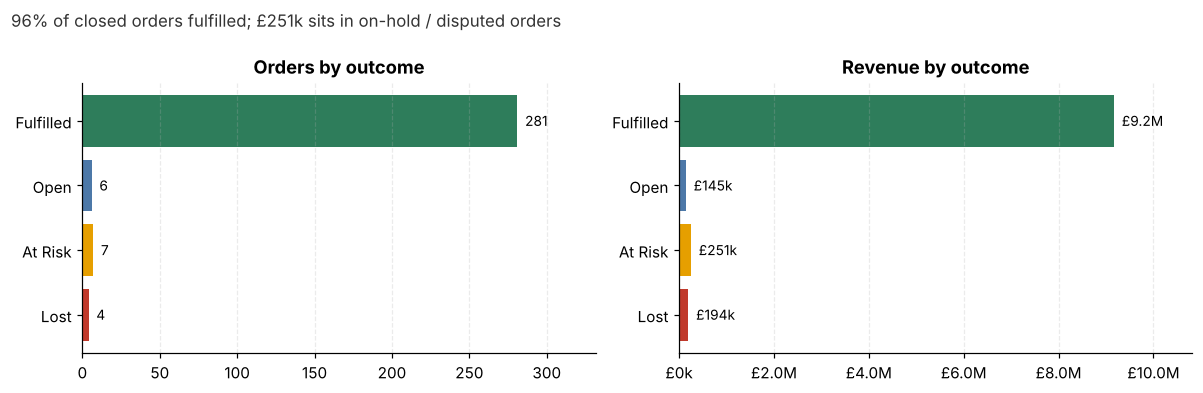

In [7]:
_ = plots.status_mix(orders)

**What changed vs v1:** Revenue at Risk falls from £590k to **£251k**. v1 added in £145k of normal open orders and £194k already lost to cancellations. Lost revenue is now reported separately, because "at risk" should mean money that can still be saved.

## 5. Trend and seasonality

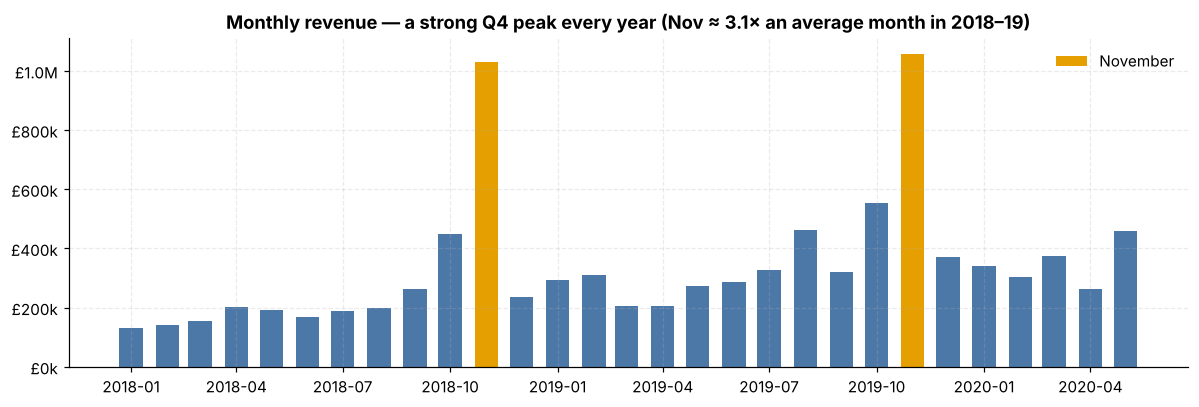

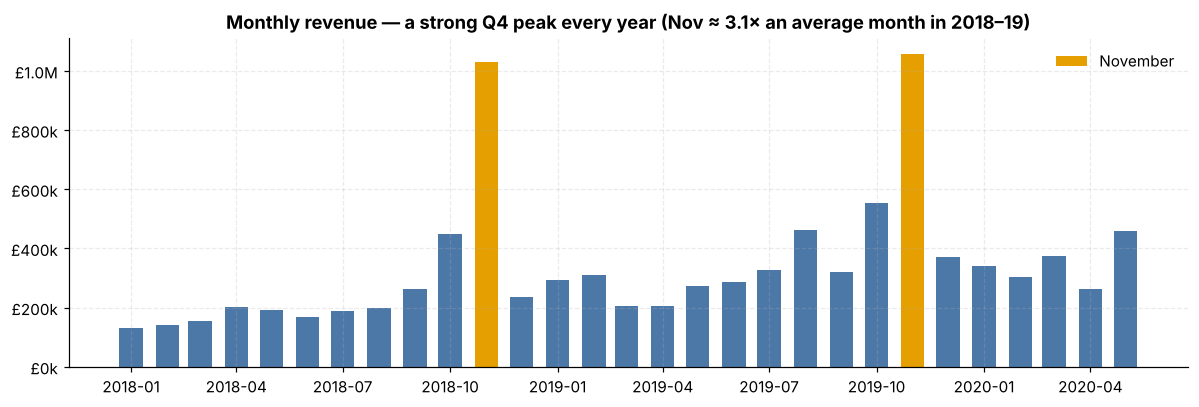

In [8]:
monthly = kpis.monthly(orders)
plots.monthly_revenue(monthly)

In [9]:
ytd = monthly[monthly.order_month.dt.month <= 5].groupby(monthly.order_month.dt.year).total_revenue.sum()
(ytd.to_frame("Jan–May revenue").assign(growth=ytd.pct_change()))

,Jan–May revenue,growth
order_month,,
2018,"820,681.77",NaN
2019,"1,289,427.87",0.5712
2020,"1,737,283.09",0.3473


Revenue peaks every November, and comparable Jan–May revenue grew year on year. 2020 is a partial year, so always compare like-for-like periods.

## 6. Country risk, with sample size in view

In [10]:
country = kpis.by_country(orders)
country[["country", "region", "total_orders", "total_revenue", "failed_orders", "failure_rate", "revenue_at_risk", "low_sample_flag"]]

,country,region,total_orders,total_revenue,failed_orders,failure_rate,revenue_at_risk,low_sample_flag
0,USA,North America,103.00,"3,355,575.69",1.00,0.0097,"152,718.98",0
1,Spain,EMEA,36.00,"1,215,686.92",2.00,0.0556,"31,821.90",0
2,France,EMEA,37.00,"1,110,916.52",0.0000,0.0000,0.0000,0
3,Australia,APAC,19.00,"630,623.10",1.00,0.0526,"14,378.09",0
4,UK,EMEA,13.00,"478,880.46",1.00,0.0769,0.0000,0
5,Italy,EMEA,8.00,"374,674.31",0.0000,0.0000,0.0000,1
6,Finland,EMEA,9.00,"329,581.91",0.0000,0.0000,0.0000,1
7,Norway,EMEA,9.00,"307,463.70",0.0000,0.0000,0.0000,1
8,Singapore,APAC,9.00,"288,488.41",0.0000,0.0000,0.0000,1
9,Denmark,EMEA,7.00,"245,637.15",1.00,0.1429,"26,012.87",1


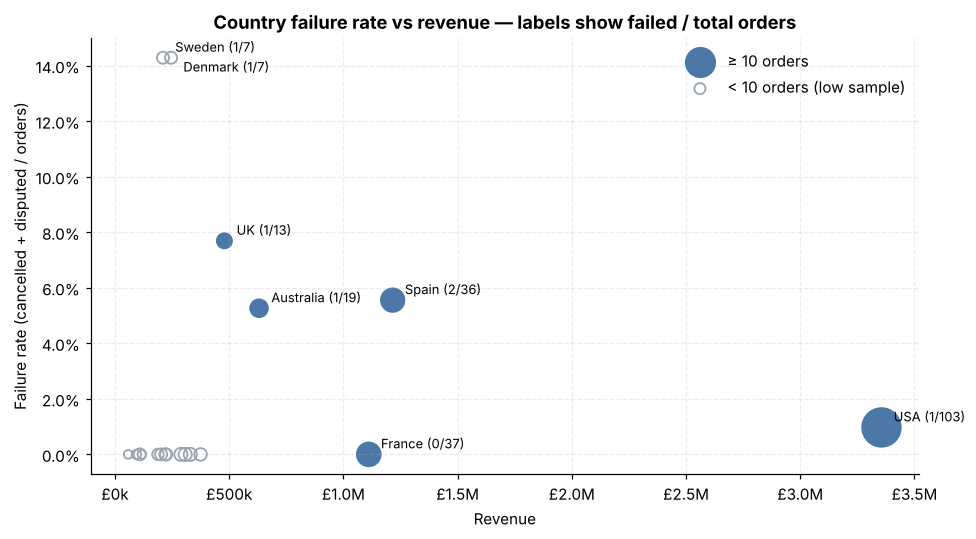

In [11]:
_ = plots.country_risk(country)

Sweden and Denmark top the failure ranking at 14.3%, but each is **one failed order out of seven**. With fewer than 10 orders, a single order moves the rate by more than 10 points, so these markets are flagged rather than ranked. Among markets with enough volume, the **UK (1/13)** and **Spain (2/36)** are worth watching.

## 7. Product lines: exact revenue, not allocation

In [12]:
cmp = kpis.equal_split_product_revenue(lines, orders)
cmp

,product_line,v2_exact,v1_equal_split,v1_error_pct
0,Classic Cars,"3,842,868.54","3,546,960.25",-0.0770
1,Vintage Cars,"1,806,675.68","2,115,744.14",0.1711
2,Trucks and Buses,"1,111,559.19","1,040,627.25",-0.0638
3,Motorcycles,"1,103,512.19","1,165,411.84",0.0561
4,Planes,"969,323.42","726,815.09",-0.2502
5,Ships,"700,039.22","626,499.09",-0.1051
6,Trains,"226,243.47","538,164.04",1.38


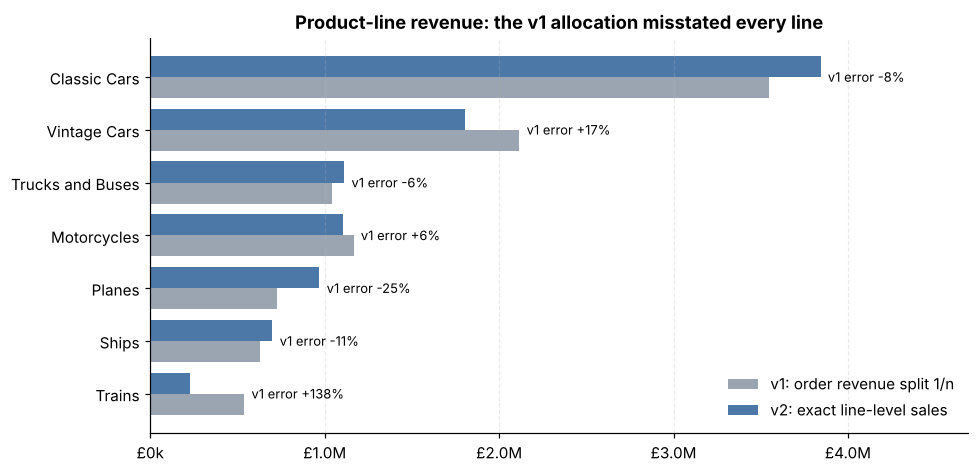

In [13]:
_ = plots.product_line_fix(cmp)

v1 split each **order's** revenue equally across the product lines in it. But every order line already carries its own `SALES` value, so no allocation is needed. The equal split overstated Trains by 138% and understated Planes by 25%.

In [14]:
pl = kpis.product_line_summary(kpis.by_product_line_month(lines), lines)
pl

,product_line,revenue,revenue_at_risk,revenue_lost,units,orders,revenue_share,revenue_at_risk_pct,revenue_lost_pct
0,Classic Cars,"3,842,868.54","75,052.52","59,242.81",33373,193,0.3937,0.0195,0.0154
1,Vintage Cars,"1,806,675.68","48,016.87","38,063.89",20059,169,0.1851,0.0266,0.0211
2,Trucks and Buses,"1,111,559.19","20,193.29",0.0000,10579,71,0.1139,0.0182,0.0000
3,Motorcycles,"1,103,512.19","36,814.51",0.0000,11080,70,0.1131,0.0334,0.0000
4,Planes,"969,323.42","38,571.37","35,432.71",10636,58,0.0993,0.0398,0.0366
5,Ships,"700,039.22","26,735.01","56,665.65",7989,63,0.0717,0.0382,0.0809
6,Trains,"226,243.47","5,808.48","5,082.42",2712,45,0.0232,0.0257,0.0225


**Takeaways**
- Fulfilment is strong (96% of closed orders) and lost revenue is small (2%), but £251k sits in on-hold or disputed orders that can still be recovered.
- Classic Cars brings in 39% of revenue. Ships has the highest lost-revenue share (8%).
- Low-volume countries need a sample-size flag before anyone acts on their rates.